# Prediksi Stroke dengan SVM & ANN
### Studi kasus klasifikasi pada data yang sangat tidak seimbang (*imbalanced*)

**Pertanyaan utama:** model mana yang lebih baik dalam mendeteksi pasien berisiko stroke, **SVM** atau **ANN**, dan mengapa *accuracy* saja tidak cukup untuk menjawabnya?

**Alur analisis (Tahap 1 pada roadmap):**
1. Business & data understanding
2. Data cleaning
3. Exploratory Data Analysis (EDA) beserta uji statistik
4. Preprocessing (split, imputasi, scaling, encoding, penanganan imbalance)
5. Pemodelan baseline SVM dan ANN
6. Optimasi hyperparameter (GridSearchCV + cross-validation)
7. Optimasi *decision threshold*
8. Evaluasi komprehensif di data uji (metrik, confusion matrix, ROC, PR, bootstrap CI, uji McNemar)
9. Interpretasi (permutation importance)
10. Kesimpulan & ekspor hasil (Tahap 2)

## 0. Setup

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline   # pip install imbalanced-learn (sudah ada di Colab: jika belum, jalankan !pip install -q imbalanced-learn)
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
C_NO, C_YES = '#4C78A8', '#E4572E'
def savefig(name):
    plt.tight_layout(); plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## 1. Business & Data Understanding
Stroke adalah salah satu penyebab utama kematian dan disabilitas. Dalam konteks *screening*, **melewatkan pasien yang sebenarnya berisiko (false negative) jauh lebih mahal** daripada memeriksa ulang pasien yang ternyata sehat (false positive). Ini menentukan metrik yang kita utamakan: **recall, PR-AUC, dan F2**, bukan accuracy.

Dataset: 5.110 pasien dengan 10 fitur demografis dan klinis. Target `stroke` (1 = pernah stroke).

In [2]:
FILE = 'healthcare-dataset-stroke-data-selected-columns.csv'
if not os.path.exists(FILE):
    try:                                   # Google Colab: unggah file CSV
        from google.colab import files
        files.upload()
    except ImportError:
        FILE = '/mnt/user-data/uploads/' + FILE
df = pd.read_csv(FILE)
print('Ukuran data:', df.shape)
display(df.head())
df.info()

Ukuran data: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   str    
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 439.3 KB


In [3]:
print('Duplikat baris :', df.duplicated().sum())
miss = df.isna().sum().to_frame('missing'); miss['persen'] = (miss['missing']/len(df)*100).round(2)
display(miss[miss.missing>0])
display(df.describe().T.round(2))
for c in ['gender','ever_married','work_type','Residence_type','smoking_status']:
    print(f'\n{c}:'); print(df[c].value_counts().to_string())

Duplikat baris : 0


,missing,persen
bmi,201,3.93


,count,mean,std,min,25%,50%,75%,max
age,5110.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
hypertension,5110.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00
heart_disease,5110.0,0.05,0.23,0.00,0.00,0.00,0.00,1.00
avg_glucose_level,5110.0,106.15,45.28,55.12,77.24,91.88,114.09,271.74
bmi,4909.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60
stroke,5110.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00



gender:
gender
Female    2994
Male      2115
Other        1

ever_married:
ever_married
Yes    3353
No     1757

work_type:
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22

Residence_type:
Residence_type
Urban    2596
Rural    2514

smoking_status:
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789


## 2. Data Cleaning
Temuan awal:
- `bmi` memiliki **201 nilai kosong (3,9%)**: diimputasi **median** nanti di dalam pipeline, dihitung hanya dari data latih agar tidak terjadi *data leakage*.
- `gender` memiliki satu baris `Other`; satu sampel tidak dapat dipelajari model dan akan bermasalah saat *stratified split*, sehingga dihapus.
- `smoking_status = Unknown` (30%) dipertahankan sebagai kategori tersendiri karena bisa jadi informatif.
- Nilai ekstrem pada `bmi` dan `avg_glucose_level` dicek, tetapi dipertahankan karena masih masuk akal secara klinis (obesitas berat, diabetes).

In [4]:
df = df[df['gender'] != 'Other'].reset_index(drop=True)
for c in ['bmi','avg_glucose_level']:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    n_out = ((df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)).sum()
    print(f'{c}: {n_out} outlier IQR ({n_out/len(df):.1%}), min={df[c].min()}, max={df[c].max()}')
print('Ukuran setelah cleaning:', df.shape)

bmi: 110 outlier IQR (2.2%), min=10.3, max=97.6
avg_glucose_level: 627 outlier IQR (12.3%), min=55.12, max=271.74
Ukuran setelah cleaning: (5109, 11)


## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribusi target: masalah utama dataset

stroke
0    4860
1     249
Prevalensi stroke: 4.87%   Rasio kelas: 1 : 19.5
Accuracy "model bodoh" yang selalu menebak tidak-stroke: 95.13%


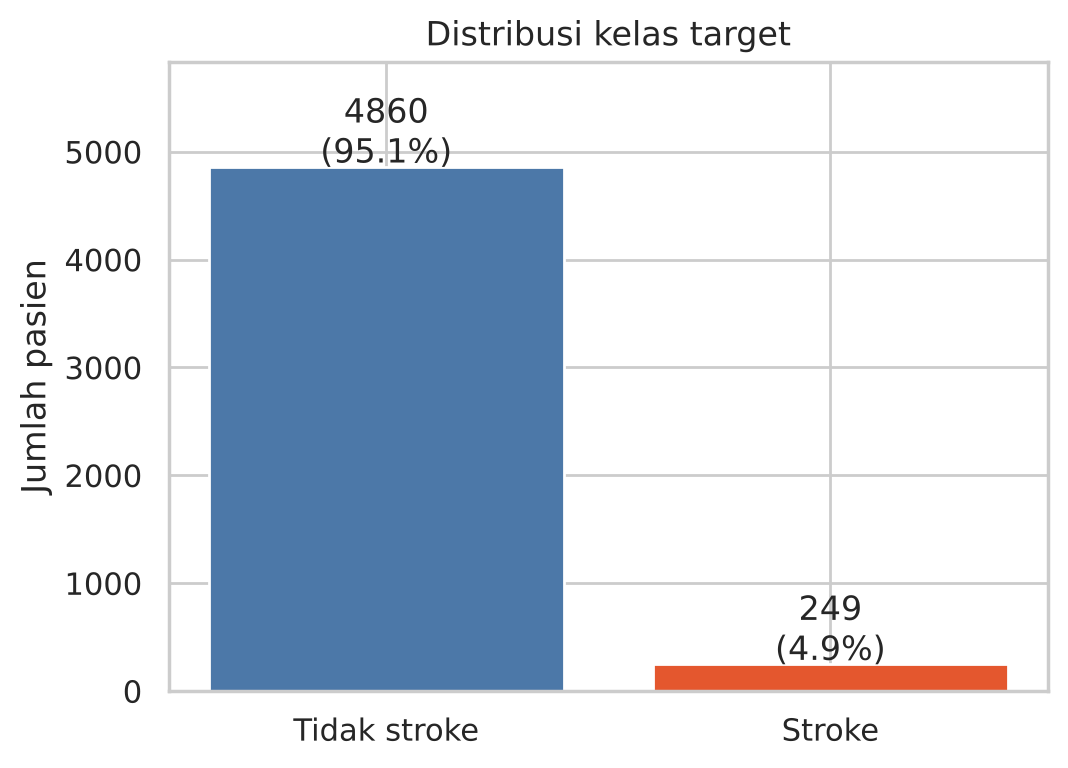

In [5]:
vc = df['stroke'].value_counts().sort_index()
print(vc.to_string()); print(f'Prevalensi stroke: {vc[1]/len(df):.2%}   Rasio kelas: 1 : {vc[0]/vc[1]:.1f}')
print(f'Accuracy "model bodoh" yang selalu menebak tidak-stroke: {vc[0]/len(df):.2%}')
fig, ax = plt.subplots(figsize=(5.5,4))
bars = ax.bar(['Tidak stroke','Stroke'], vc.values, color=[C_NO,C_YES])
for b,v in zip(bars,vc.values): ax.text(b.get_x()+b.get_width()/2, v+40, f'{v}\n({v/len(df):.1%})', ha='center')
ax.set_ylabel('Jumlah pasien'); ax.set_title('Distribusi kelas target'); ax.set_ylim(0, vc.max()*1.2)
savefig('fig01_target_distribution')

> **Insight:** hanya ±5% pasien yang mengalami stroke. Model yang selalu menjawab "tidak stroke" sudah mencapai accuracy ±95%, tetapi **tidak berguna sama sekali**. Inilah *accuracy paradox* yang akan kita buktikan pada tahap pemodelan.

### 3.2 Fitur numerik

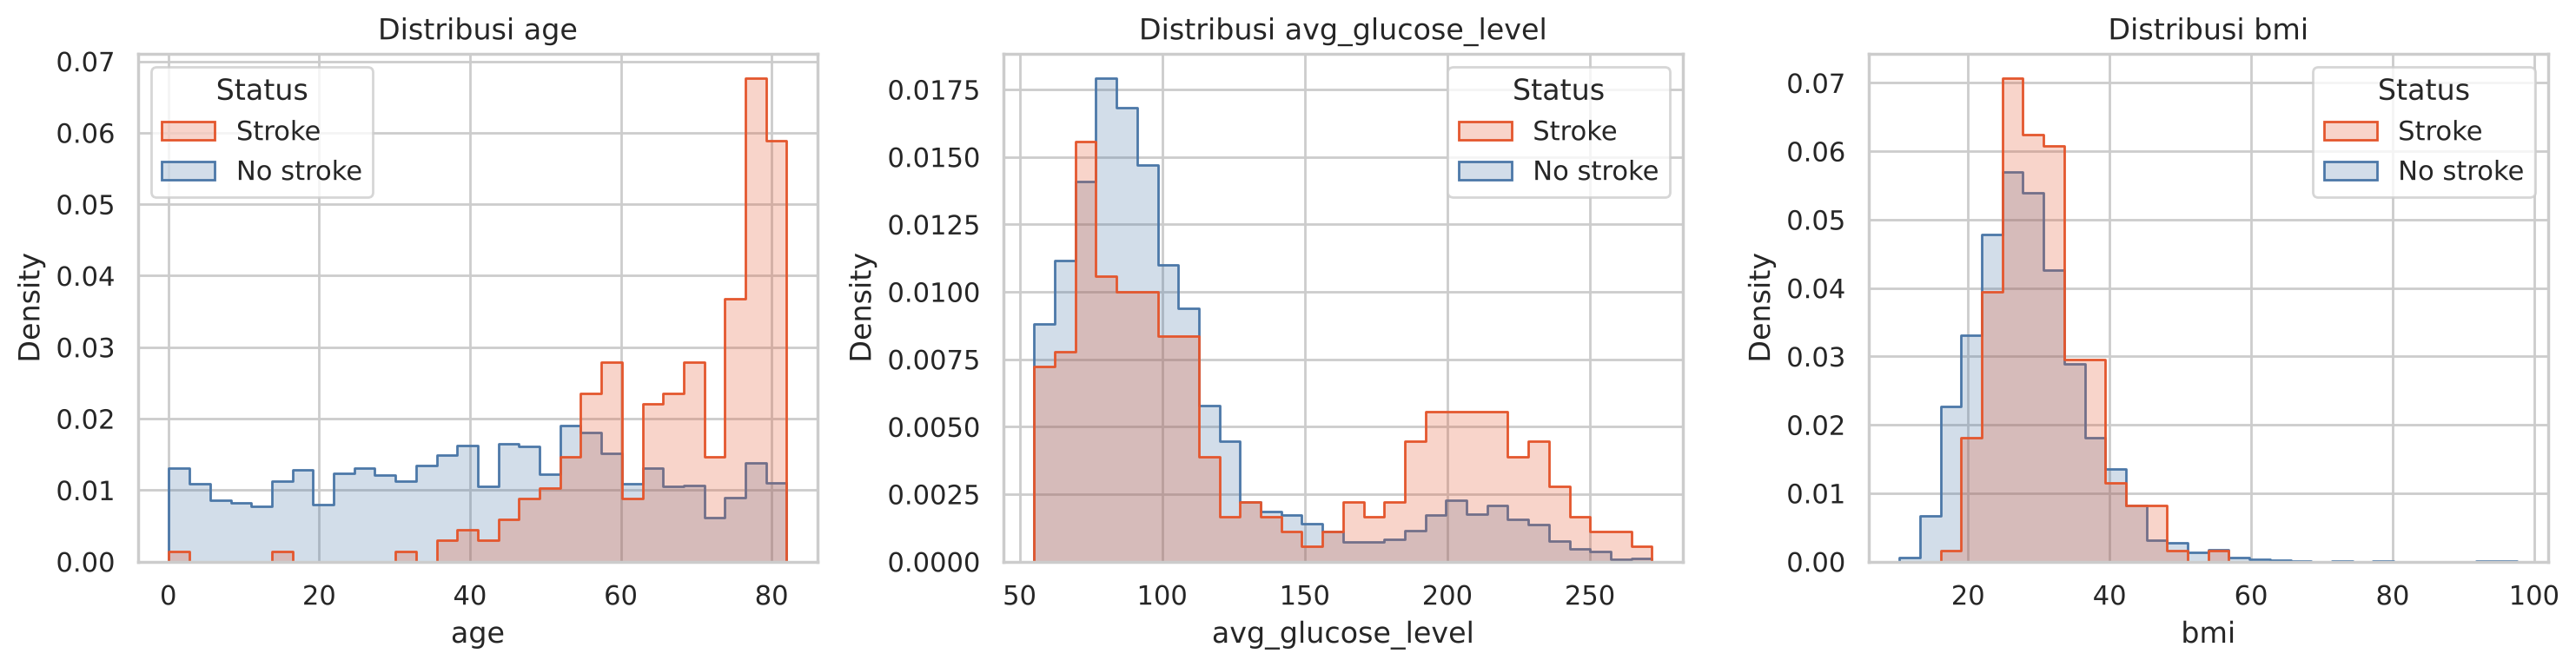

,fitur,median_tanpa_stroke,median_stroke,p_value_MannWhitney
0,age,43.0,71.0,3.849734e-71
1,avg_glucose_level,91.5,105.2,3.583095e-09
2,bmi,28.0,29.7,1.041877e-04


In [6]:
df['Status'] = df['stroke'].map({0:'No stroke',1:'Stroke'})
num_cols_eda = ['age','avg_glucose_level','bmi']
fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax,c in zip(axes,num_cols_eda):
    sns.histplot(data=df, x=c, hue='Status', stat='density', common_norm=False, bins=30, element='step',
                 palette={'No stroke':C_NO,'Stroke':C_YES}, ax=ax)
    ax.set_title(f'Distribusi {c}')
savefig('fig02_numeric_distributions')

rows=[]
for c in num_cols_eda:
    a=df.loc[df.stroke==1,c].dropna(); b=df.loc[df.stroke==0,c].dropna()
    u,p = stats.mannwhitneyu(a,b)
    rows.append([c, round(b.median(),1), round(a.median(),1), p])
mw = pd.DataFrame(rows, columns=['fitur','median_tanpa_stroke','median_stroke','p_value_MannWhitney'])
display(mw)

### 3.3 Fitur kategorikal: stroke rate per kategori

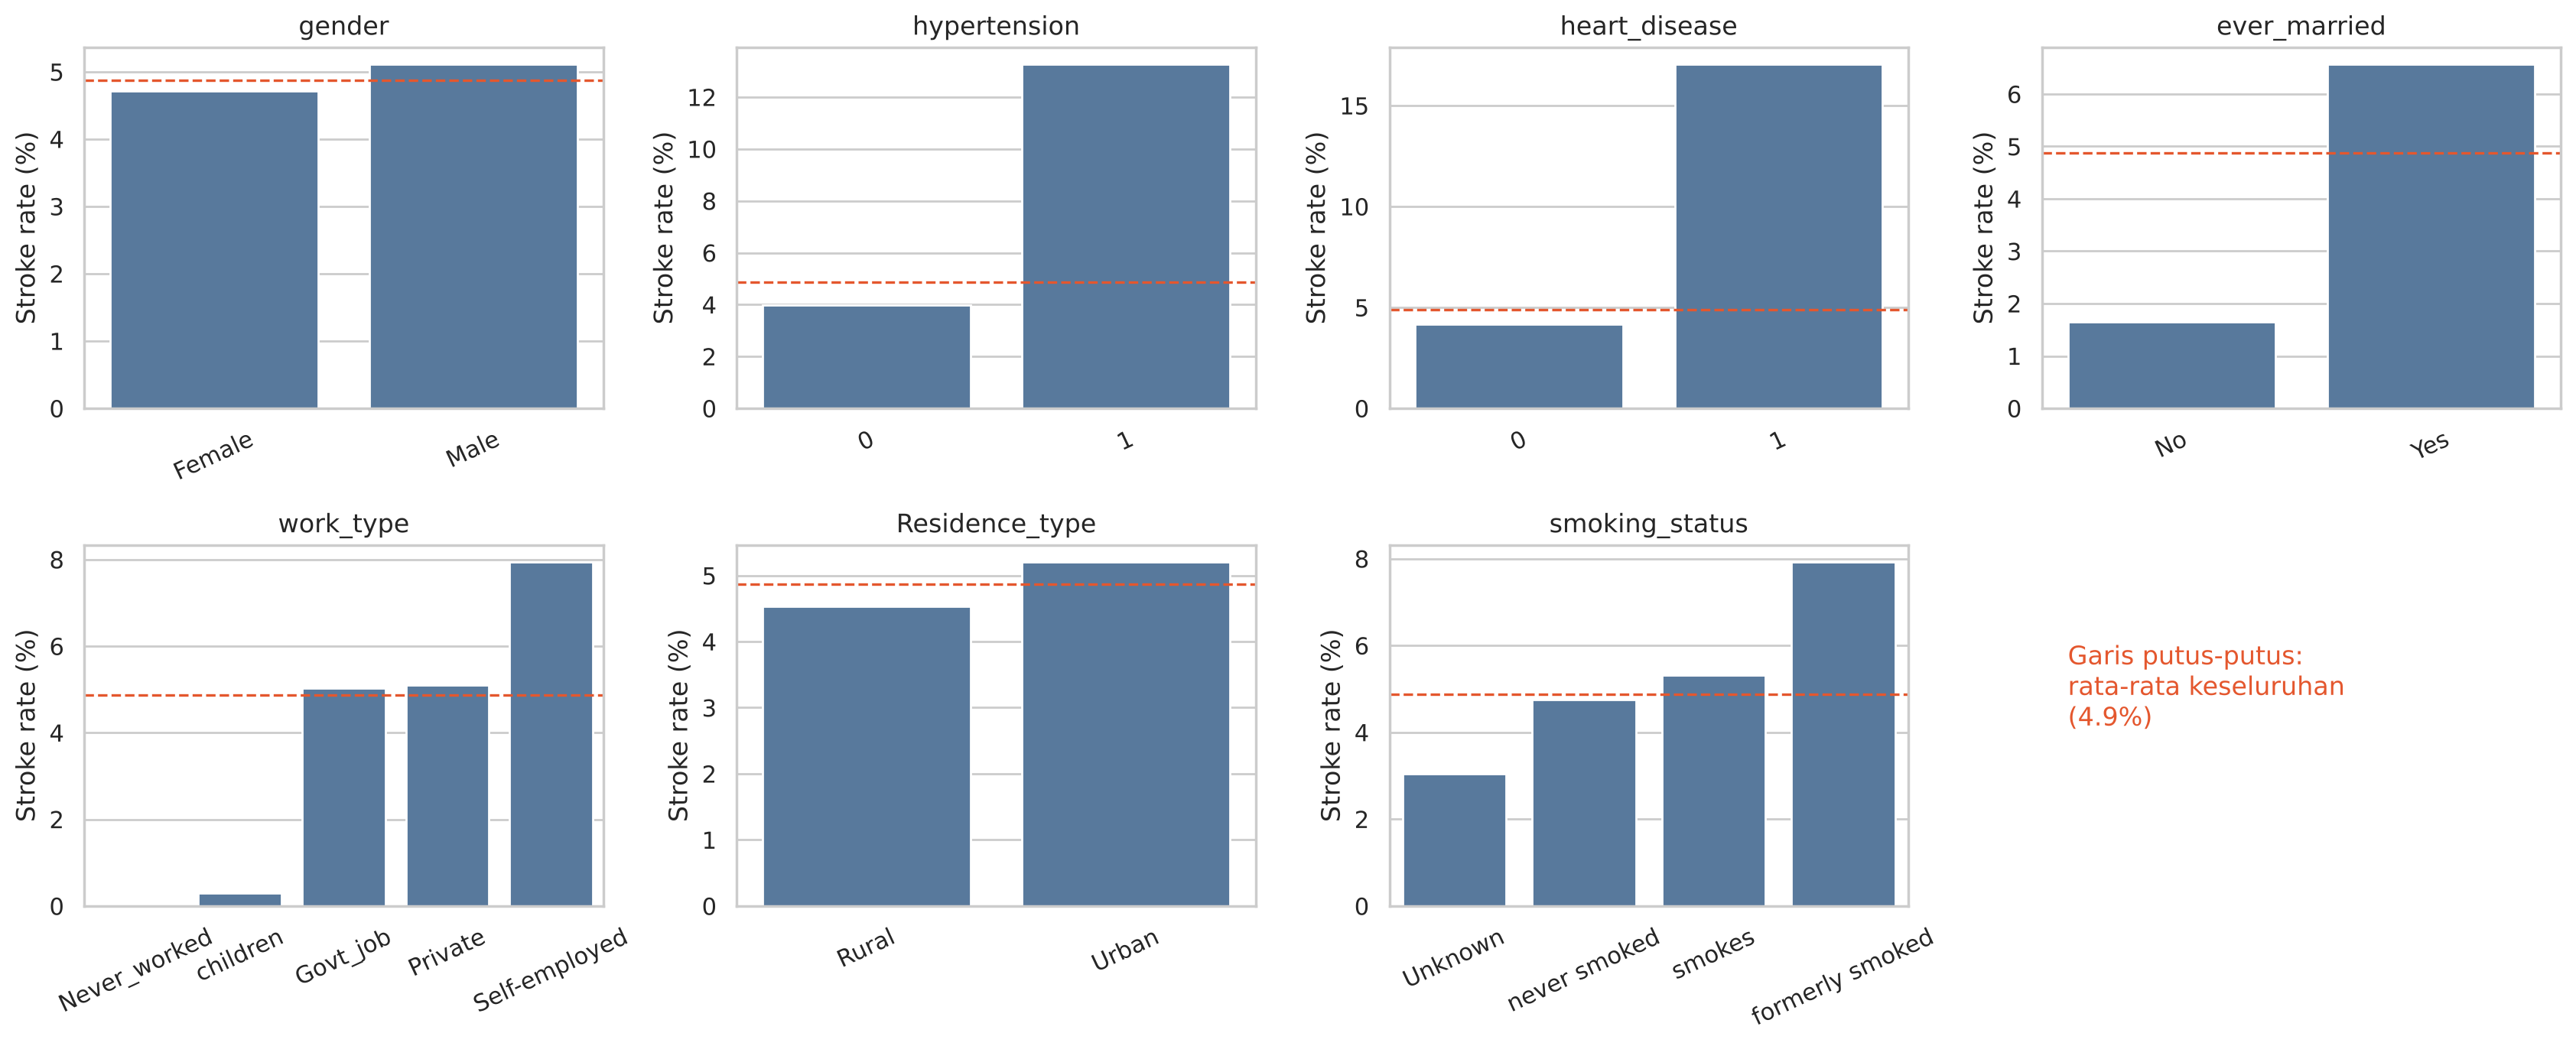

,fitur,chi2,p_value,Cramers_V
2,heart_disease,90.2,2.120831e-21,0.133
1,hypertension,81.6,1.688936e-19,0.126
3,ever_married,58.9,1.686286e-14,0.107
4,work_type,49.2,5.409035e-10,0.098
6,smoking_status,29.2,2.007704e-06,0.076
5,Residence_type,1.1,2.998252e-01,0.015
0,gender,0.3,5.598278e-01,0.008


In [7]:
cat_eda = ['gender','hypertension','heart_disease','ever_married','work_type','Residence_type','smoking_status']
fig, axes = plt.subplots(2,4, figsize=(17,7)); axes=axes.ravel()
overall = df.stroke.mean()*100
for ax,c in zip(axes,cat_eda):
    r = df.groupby(c)['stroke'].mean().mul(100).sort_values()
    sns.barplot(x=r.index.astype(str), y=r.values, color=C_NO, ax=ax)
    ax.axhline(overall, color=C_YES, ls='--', lw=1.2); ax.set_title(c); ax.set_ylabel('Stroke rate (%)'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=25)
axes[-1].axis('off'); axes[-1].text(0.05,0.5,f'Garis putus-putus:\nrata-rata keseluruhan\n({overall:.1f}%)', fontsize=12, color=C_YES)
savefig('fig03_categorical_stroke_rate')

rows=[]
for c in cat_eda:
    ct = pd.crosstab(df[c], df['stroke']); chi2,p,_,_ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))
    rows.append([c, round(chi2,1), p, round(v,3)])
chi = pd.DataFrame(rows, columns=['fitur','chi2','p_value','Cramers_V']).sort_values('Cramers_V', ascending=False)
display(chi)

### 3.4 Usia sebagai faktor dominan, serta korelasi

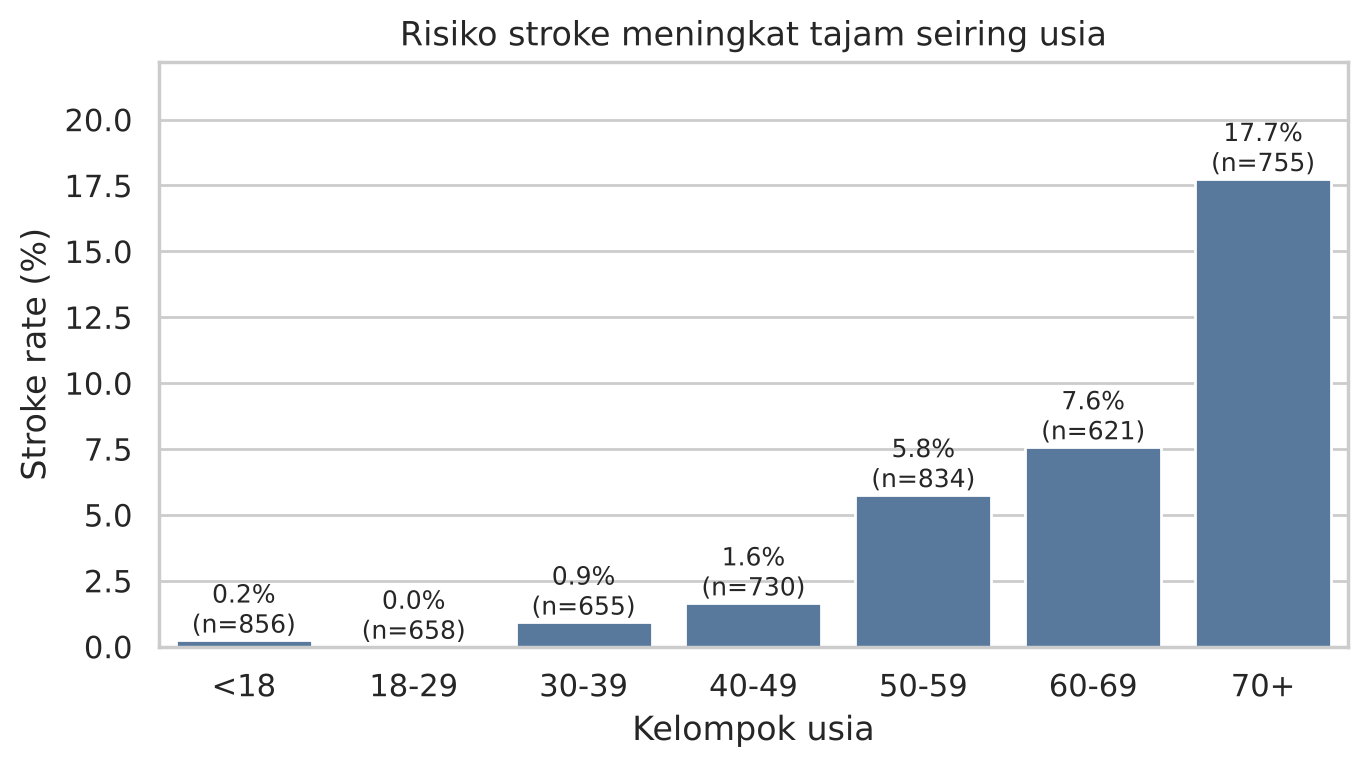

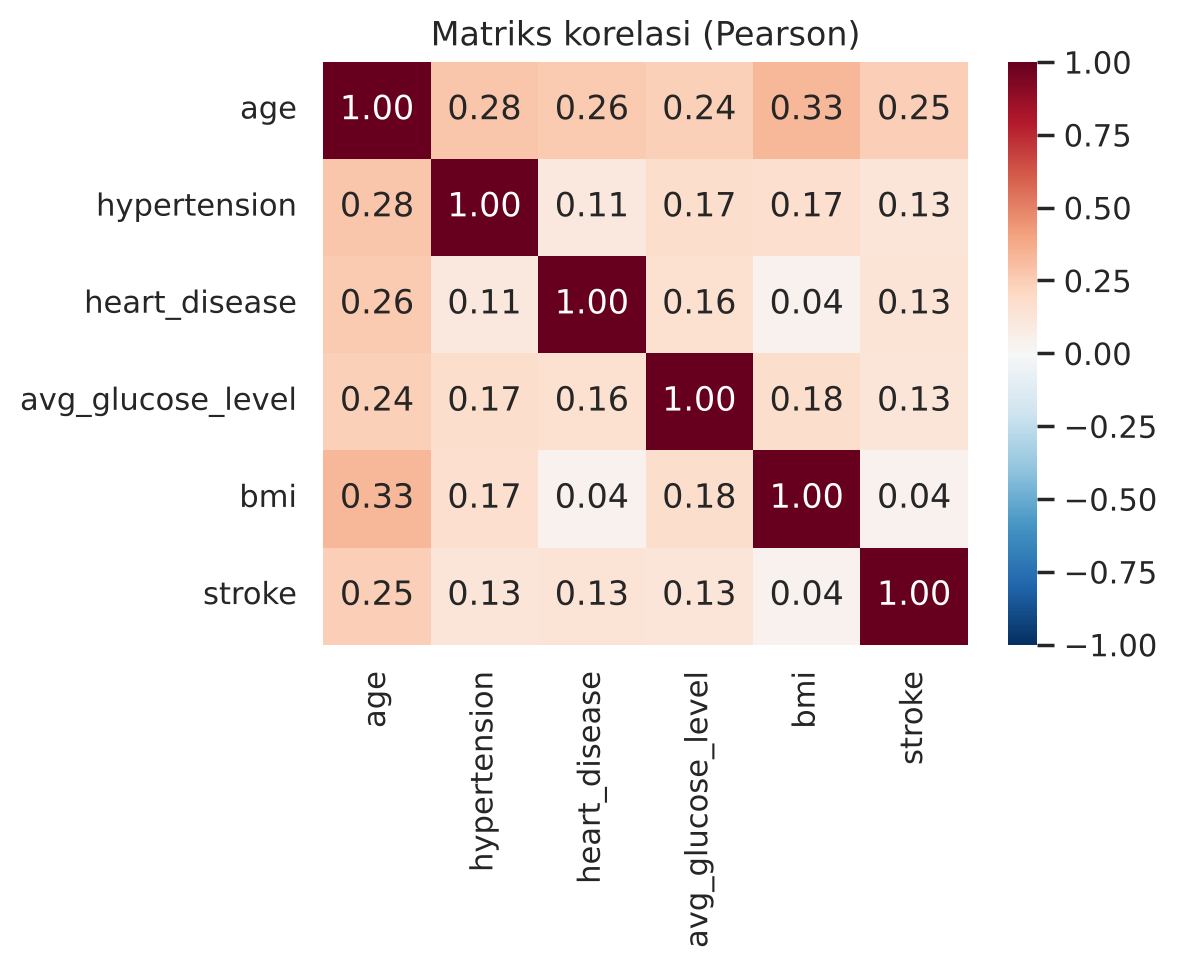

In [8]:
bins=[0,18,30,40,50,60,70,100]; labels=['<18','18-29','30-39','40-49','50-59','60-69','70+']
df['age_group']=pd.cut(df['age'],bins=bins,labels=labels,right=False)
ag = df.groupby('age_group', observed=True)['stroke'].agg(['mean','sum','count']); ag['mean']*=100
fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(x=ag.index, y=ag['mean'], color=C_NO, ax=ax)
for i,(m,n) in enumerate(zip(ag['mean'],ag['count'])): ax.text(i, m+0.3, f'{m:.1f}%\n(n={n})', ha='center', fontsize=9)
ax.set_ylabel('Stroke rate (%)'); ax.set_xlabel('Kelompok usia'); ax.set_title('Risiko stroke meningkat tajam seiring usia'); ax.set_ylim(0, ag['mean'].max()*1.25)
savefig('fig04_stroke_by_age_group')

fig, ax = plt.subplots(figsize=(6,5))
corr = df[['age','hypertension','heart_disease','avg_glucose_level','bmi','stroke']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Matriks korelasi (Pearson)')
savefig('fig05_correlation_heatmap')

> **Insight EDA:**
> - **Usia** adalah pembeda paling kuat: pasien stroke jauh lebih tua, dan stroke rate melonjak pada usia 60+.
> - `hypertension`, `heart_disease`, `avg_glucose_level`, dan `ever_married` berhubungan signifikan dengan stroke. Catatan: `ever_married` kemungkinan hanya *proxy* usia (bukan sebab).
> - `Residence_type` dan `gender` hampir tidak informatif.
> - Korelasi antar-fitur umumnya rendah-sedang, tidak ada multikolinearitas serius.
> - Semua sinyal bersifat **lemah-sedang**, sehingga kita tidak boleh berharap performa sempurna.

## 4. Preprocessing
Prinsip yang dipakai: **semua langkah yang "belajar dari data" (imputasi, scaling, encoding, SMOTE) hanya boleh dipelajari dari data latih.** Karena itu semuanya dimasukkan ke dalam `Pipeline`, sehingga di setiap lipatan cross-validation tidak ada kebocoran informasi dari data validasi.

| Langkah | Kolom | Alasan |
|---|---|---|
| Imputasi median + StandardScaler | `age`, `avg_glucose_level`, `bmi` | SVM (RBF) dan ANN sangat sensitif terhadap skala fitur |
| One-Hot Encoding | `gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status` | Mengubah kategori menjadi numerik tanpa urutan palsu |
| Passthrough | `hypertension`, `heart_disease` | Sudah biner 0/1 |
| Stratified split 80/20 | seluruh data | Menjaga proporsi stroke ±5% pada data latih dan uji |

In [9]:
df = df.drop(columns=['Status','age_group'])
X = df.drop(columns='stroke'); y = df['stroke']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}  stroke={y_train.sum()} ({y_train.mean():.2%})')
print(f'Test : {X_test.shape}   stroke={y_test.sum()} ({y_test.mean():.2%})')

num_cols = ['age','avg_glucose_level','bmi']
cat_cols = ['gender','ever_married','work_type','Residence_type','smoking_status']
bin_cols = ['hypertension','heart_disease']
def make_prep():
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('bin', 'passthrough', bin_cols)])
p = make_prep().fit(X_train)
print('Jumlah fitur setelah preprocessing:', len(p.get_feature_names_out()))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (4087, 10)  stroke=199 (4.87%)
Test : (1022, 10)   stroke=50 (4.89%)
Jumlah fitur setelah preprocessing: 20


**Penanganan imbalance.** Dua strategi dipakai sesuai karakter model:
- **SVM:** `class_weight='balanced'` (memberi penalti lebih besar untuk kesalahan pada kelas stroke).
- **ANN:** **SMOTE** (membuat sampel sintetis kelas minoritas), karena `MLPClassifier` scikit-learn tidak memiliki `class_weight`. SMOTE diterapkan **hanya pada data latih di dalam pipeline**, dan data uji tidak pernah disentuh.

> Catatan metodologis: SMOTE dijalankan setelah one-hot encoding, sehingga sampel sintetis pada kolom kategori bernilai pecahan. SMOTENC bisa menjadi alternatif yang lebih ketat.

## 5. Pemodelan Baseline: membuktikan *accuracy paradox*

**Cara kerja singkat:**
- **SVM** mencari *hyperplane* pemisah dengan margin terbesar. Dengan kernel **RBF**, data dipetakan implisit ke ruang berdimensi tinggi agar batas non-linear bisa dibentuk. Parameter `C` mengatur toleransi kesalahan dan `gamma` mengatur jangkauan pengaruh tiap sampel.
- **ANN (MLP)** menyusun neuron berlapis. Bobot dipelajari lewat *backpropagation* dan *gradient descent* untuk meminimalkan *log-loss*. Hyperparameter penting adalah arsitektur, regularisasi `alpha`, dan *learning rate*.

In [10]:
def get_scores(model, X):
    return model.decision_function(X) if hasattr(model, 'decision_function') else model.predict_proba(X)[:,1]

def evaluate(name, y_true, scores, thr):
    pred = (scores >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return dict(Model=name, Threshold=round(float(thr),3),
        Accuracy=accuracy_score(y_true,pred), Balanced_Acc=balanced_accuracy_score(y_true,pred),
        Precision=precision_score(y_true,pred,zero_division=0), Recall=recall_score(y_true,pred),
        Specificity=tn/(tn+fp), F1=f1_score(y_true,pred), F2=fbeta_score(y_true,pred,beta=2),
        ROC_AUC=roc_auc_score(y_true,scores), PR_AUC=average_precision_score(y_true,scores),
        MCC=matthews_corrcoef(y_true,pred), TN=tn, FP=fp, FN=fn, TP=tp)

models, thr, scores_te = {}, {}, {}
def register(name, est, threshold):
    models[name]=est; thr[name]=threshold; scores_te[name]=get_scores(est, X_test)

svm_base = Pipeline([('prep',make_prep()), ('clf',SVC(kernel='rbf', random_state=RANDOM_STATE))]).fit(X_train,y_train)
register('SVM baseline', svm_base, 0.0)
svm_bal = Pipeline([('prep',make_prep()), ('clf',SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE))]).fit(X_train,y_train)
register('SVM + class_weight', svm_bal, 0.0)

ann_base = Pipeline([('prep',make_prep()), ('clf',MLPClassifier(hidden_layer_sizes=(64,32), max_iter=300,
            early_stopping=True, random_state=RANDOM_STATE))]).fit(X_train,y_train)
register('ANN baseline', ann_base, 0.5)
ann_smote = ImbPipeline([('prep',make_prep()), ('smote',SMOTE(random_state=RANDOM_STATE)),
            ('clf',MLPClassifier(hidden_layer_sizes=(64,32), max_iter=200, random_state=RANDOM_STATE))]).fit(X_train,y_train)
register('ANN + SMOTE', ann_smote, 0.5)

tab = pd.DataFrame([evaluate(n, y_test, scores_te[n], thr[n]) for n in models]).set_index('Model')
display(tab[['Accuracy','Precision','Recall','F1','ROC_AUC','PR_AUC','TP','FN','FP']].round(3))

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FN,FP
Model,,,,,,,,,
SVM baseline,0.951,0.000,0.00,0.000,0.696,0.122,0,50,0
SVM + class_weight,0.745,0.119,0.66,0.202,0.787,0.159,33,17,244
ANN baseline,0.951,0.000,0.00,0.000,0.350,0.037,0,50,0
ANN + SMOTE,0.899,0.104,0.14,0.120,0.694,0.110,7,43,60


> **Accuracy paradox terbukti:** baseline SVM dan ANN tanpa penanganan imbalance memiliki accuracy tinggi (±95%), tetapi hampir tidak menemukan pasien stroke (recall ≈ 0). Saat imbalance ditangani, accuracy justru **turun**, namun recall naik tajam. Penurunan accuracy ini adalah harga yang wajar untuk model yang benar-benar berguna.

## 6. Optimasi Hyperparameter
Memakai `GridSearchCV` dengan **5-fold stratified cross-validation** pada data latih. Metrik seleksi: **ROC-AUC**, yang tidak bergantung pada threshold sehingga adil untuk membandingkan konfigurasi. Optimasi threshold dilakukan terpisah pada bagian 7.

In [11]:
svm_grid = GridSearchCV(
    Pipeline([('prep',make_prep()), ('clf',SVC(class_weight='balanced', random_state=RANDOM_STATE))]),
    param_grid=[{'clf__kernel':['rbf'], 'clf__C':[0.1,1,10], 'clf__gamma':[0.005,0.02,'scale']},
                {'clf__kernel':['linear'], 'clf__C':[0.01,0.1,1]}],
    scoring='roc_auc', cv=cv, n_jobs=-1, refit=True).fit(X_train, y_train)
print('Best SVM params :', svm_grid.best_params_); print(f'Best CV ROC-AUC : {svm_grid.best_score_:.4f}')
cols = ['params','mean_test_score','std_test_score','rank_test_score']
display(pd.DataFrame(svm_grid.cv_results_)[cols].sort_values('rank_test_score').head(5))

Best SVM params : {'clf__C': 1, 'clf__gamma': 0.005, 'clf__kernel': 'rbf'}
Best CV ROC-AUC : 0.8412


,params,mean_test_score,std_test_score,rank_test_score
3,"{'clf__C': 1, 'clf__gamma': 0.005, 'clf__kerne...",0.841161,0.018448,1
9,"{'clf__C': 0.01, 'clf__kernel': 'linear'}",0.841065,0.018388,2
10,"{'clf__C': 0.1, 'clf__kernel': 'linear'}",0.840228,0.018991,3
1,"{'clf__C': 0.1, 'clf__gamma': 0.02, 'clf__kern...",0.839736,0.019833,4
11,"{'clf__C': 1, 'clf__kernel': 'linear'}",0.839518,0.019021,5


In [12]:
ann_grid = GridSearchCV(
    ImbPipeline([('prep',make_prep()), ('smote',SMOTE(random_state=RANDOM_STATE)),
                 ('clf',MLPClassifier(max_iter=200, random_state=RANDOM_STATE))]),
    param_grid={'clf__hidden_layer_sizes':[(16,),(32,16),(64,32)],
                'clf__alpha':[1e-4,1e-2,1e-1], 'clf__learning_rate_init':[1e-3,1e-2]},
    scoring='roc_auc', cv=cv, n_jobs=-1, refit=True).fit(X_train, y_train)
print('Best ANN params :', ann_grid.best_params_); print(f'Best CV ROC-AUC : {ann_grid.best_score_:.4f}')
display(pd.DataFrame(ann_grid.cv_results_)[cols].sort_values('rank_test_score').head(5))

Best ANN params : {'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (16,), 'clf__learning_rate_init': 0.001}
Best CV ROC-AUC : 0.7904


,params,mean_test_score,std_test_score,rank_test_score
12,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.790371,0.028810,1
6,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes'...",0.786043,0.029966,2
0,"{'clf__alpha': 0.0001, 'clf__hidden_layer_size...",0.785309,0.030018,3
13,"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes':...",0.777783,0.024221,4
7,"{'clf__alpha': 0.01, 'clf__hidden_layer_sizes'...",0.755973,0.026743,5


## 7. Optimasi Decision Threshold
Threshold bawaan (0,5 untuk ANN, 0 untuk SVM) bukan yang terbaik untuk *screening*. Threshold dipilih dengan memaksimalkan **F2-score** (recall dibobot 2× lebih penting dari precision) pada **prediksi out-of-fold data latih**, sehingga data uji tetap murni untuk evaluasi akhir.

Threshold optimal SVM: 0.300   |   ANN: 0.300


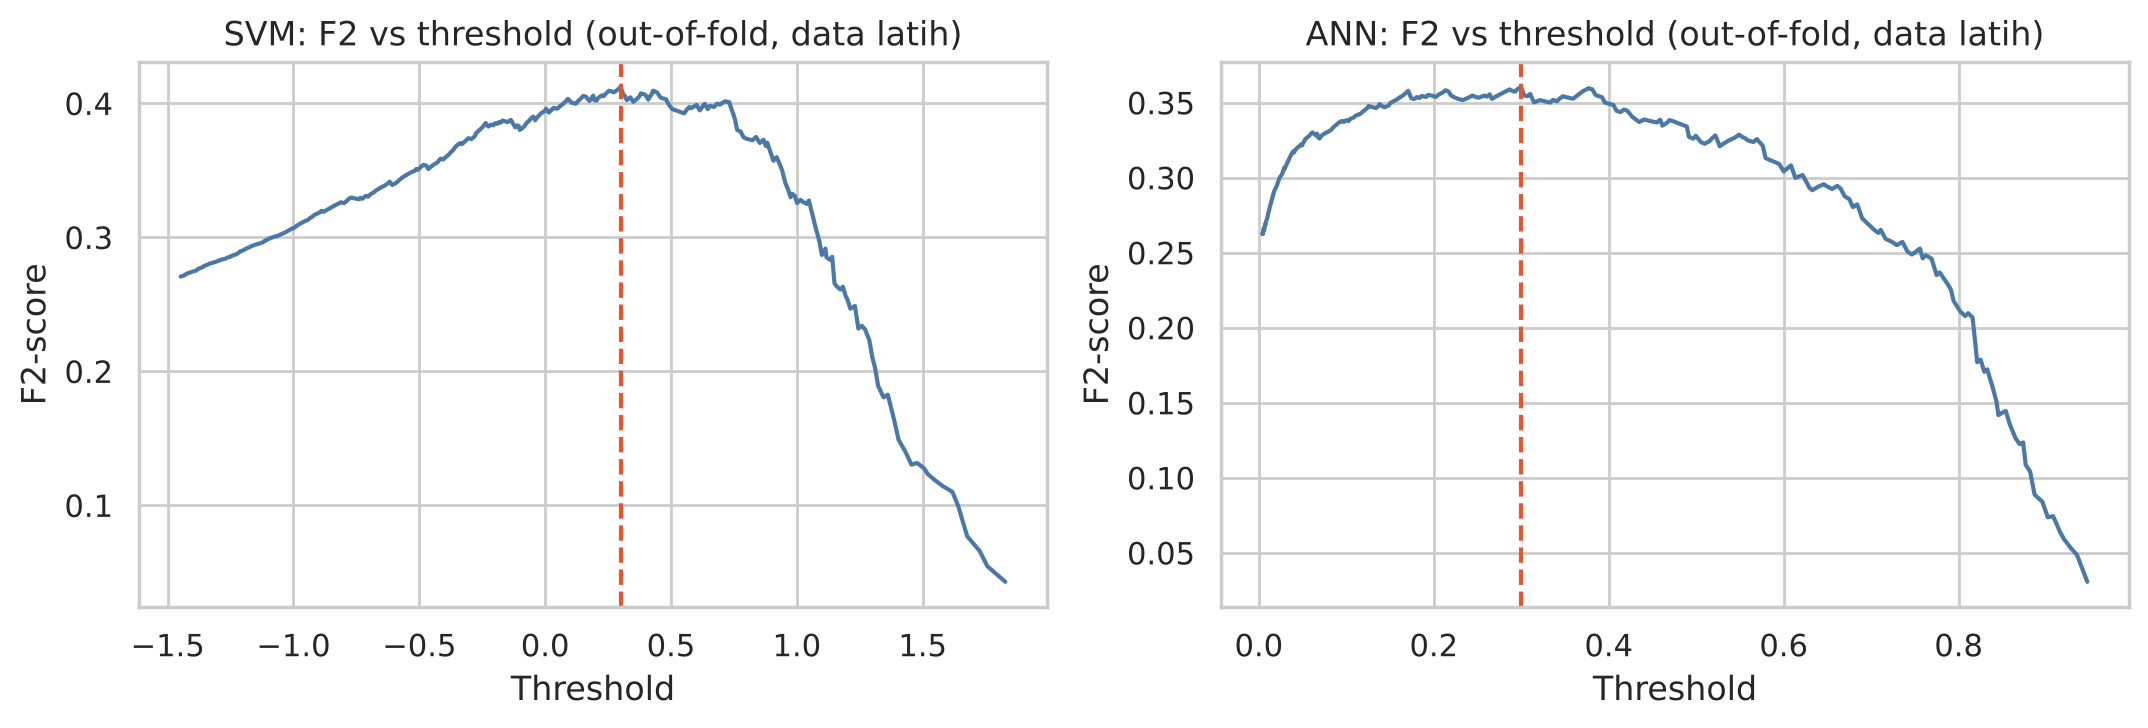

In [13]:
def tune_threshold(est, Xtr, ytr, beta=2):
    method = 'decision_function' if hasattr(est,'decision_function') else 'predict_proba'
    oof = cross_val_predict(clone(est), Xtr, ytr, cv=cv, method=method)
    oof = oof[:,1] if oof.ndim==2 else oof
    grid = np.unique(np.quantile(oof, np.linspace(0.30, 0.995, 300)))
    f = np.array([fbeta_score(ytr, (oof>=t).astype(int), beta=beta) for t in grid])
    return grid[f.argmax()], grid, f

svm_best, ann_best = svm_grid.best_estimator_, ann_grid.best_estimator_
t_svm, g_svm, f_svm = tune_threshold(svm_best, X_train, y_train)
t_ann, g_ann, f_ann = tune_threshold(ann_best, X_train, y_train)
print(f'Threshold optimal SVM: {t_svm:.3f}   |   ANN: {t_ann:.3f}')

register('SVM tuned (thr 0)',  svm_best, 0.0)
register('ANN tuned (thr 0.5)', ann_best, 0.5)
models['SVM tuned + thr'] = svm_best; thr['SVM tuned + thr']=t_svm; scores_te['SVM tuned + thr']=scores_te['SVM tuned (thr 0)']
models['ANN tuned + thr'] = ann_best; thr['ANN tuned + thr']=t_ann; scores_te['ANN tuned + thr']=scores_te['ANN tuned (thr 0.5)']

fig, axes = plt.subplots(1,2, figsize=(11,3.8))
for ax,(g,f,t,n) in zip(axes,[(g_svm,f_svm,t_svm,'SVM'),(g_ann,f_ann,t_ann,'ANN')]):
    ax.plot(g,f,color=C_NO); ax.axvline(t,color=C_YES,ls='--'); ax.set_title(f'{n}: F2 vs threshold (out-of-fold, data latih)')
    ax.set_xlabel('Threshold'); ax.set_ylabel('F2-score')
savefig('fig06_threshold_optimization')

## 8. Evaluasi Akhir pada Data Uji
Data uji (1.022 pasien, 50 kasus stroke) baru dipakai di tahap ini.

In [14]:
order = ['SVM baseline','SVM + class_weight','SVM tuned (thr 0)','SVM tuned + thr',
         'ANN baseline','ANN + SMOTE','ANN tuned (thr 0.5)','ANN tuned + thr']
res = pd.DataFrame([evaluate(n, y_test, scores_te[n], thr[n]) for n in order]).set_index('Model')
res.to_csv('results/model_comparison.csv')
display(res[['Threshold','Accuracy','Balanced_Acc','Precision','Recall','Specificity','F1','F2','ROC_AUC','PR_AUC','MCC']].round(3))

,Threshold,Accuracy,Balanced_Acc,Precision,Recall,Specificity,F1,F2,ROC_AUC,PR_AUC,MCC
Model,,,,,,,,,,,
SVM baseline,0.0,0.951,0.500,0.000,0.00,1.000,0.000,0.000,0.696,0.122,0.000
SVM + class_weight,0.0,0.745,0.704,0.119,0.66,0.749,0.202,0.346,0.787,0.159,0.198
SVM tuned (thr 0),0.0,0.703,0.758,0.122,0.82,0.697,0.212,0.382,0.838,0.273,0.237
SVM tuned + thr,0.3,0.777,0.778,0.152,0.78,0.777,0.255,0.428,0.838,0.273,0.277
ANN baseline,0.5,0.951,0.500,0.000,0.00,1.000,0.000,0.000,0.350,0.037,0.000
ANN + SMOTE,0.5,0.899,0.539,0.104,0.14,0.938,0.120,0.131,0.694,0.110,0.068
ANN tuned (thr 0.5),0.5,0.766,0.697,0.124,0.62,0.774,0.206,0.344,0.786,0.157,0.197
ANN tuned + thr,0.3,0.677,0.688,0.100,0.70,0.676,0.175,0.318,0.786,0.157,0.171


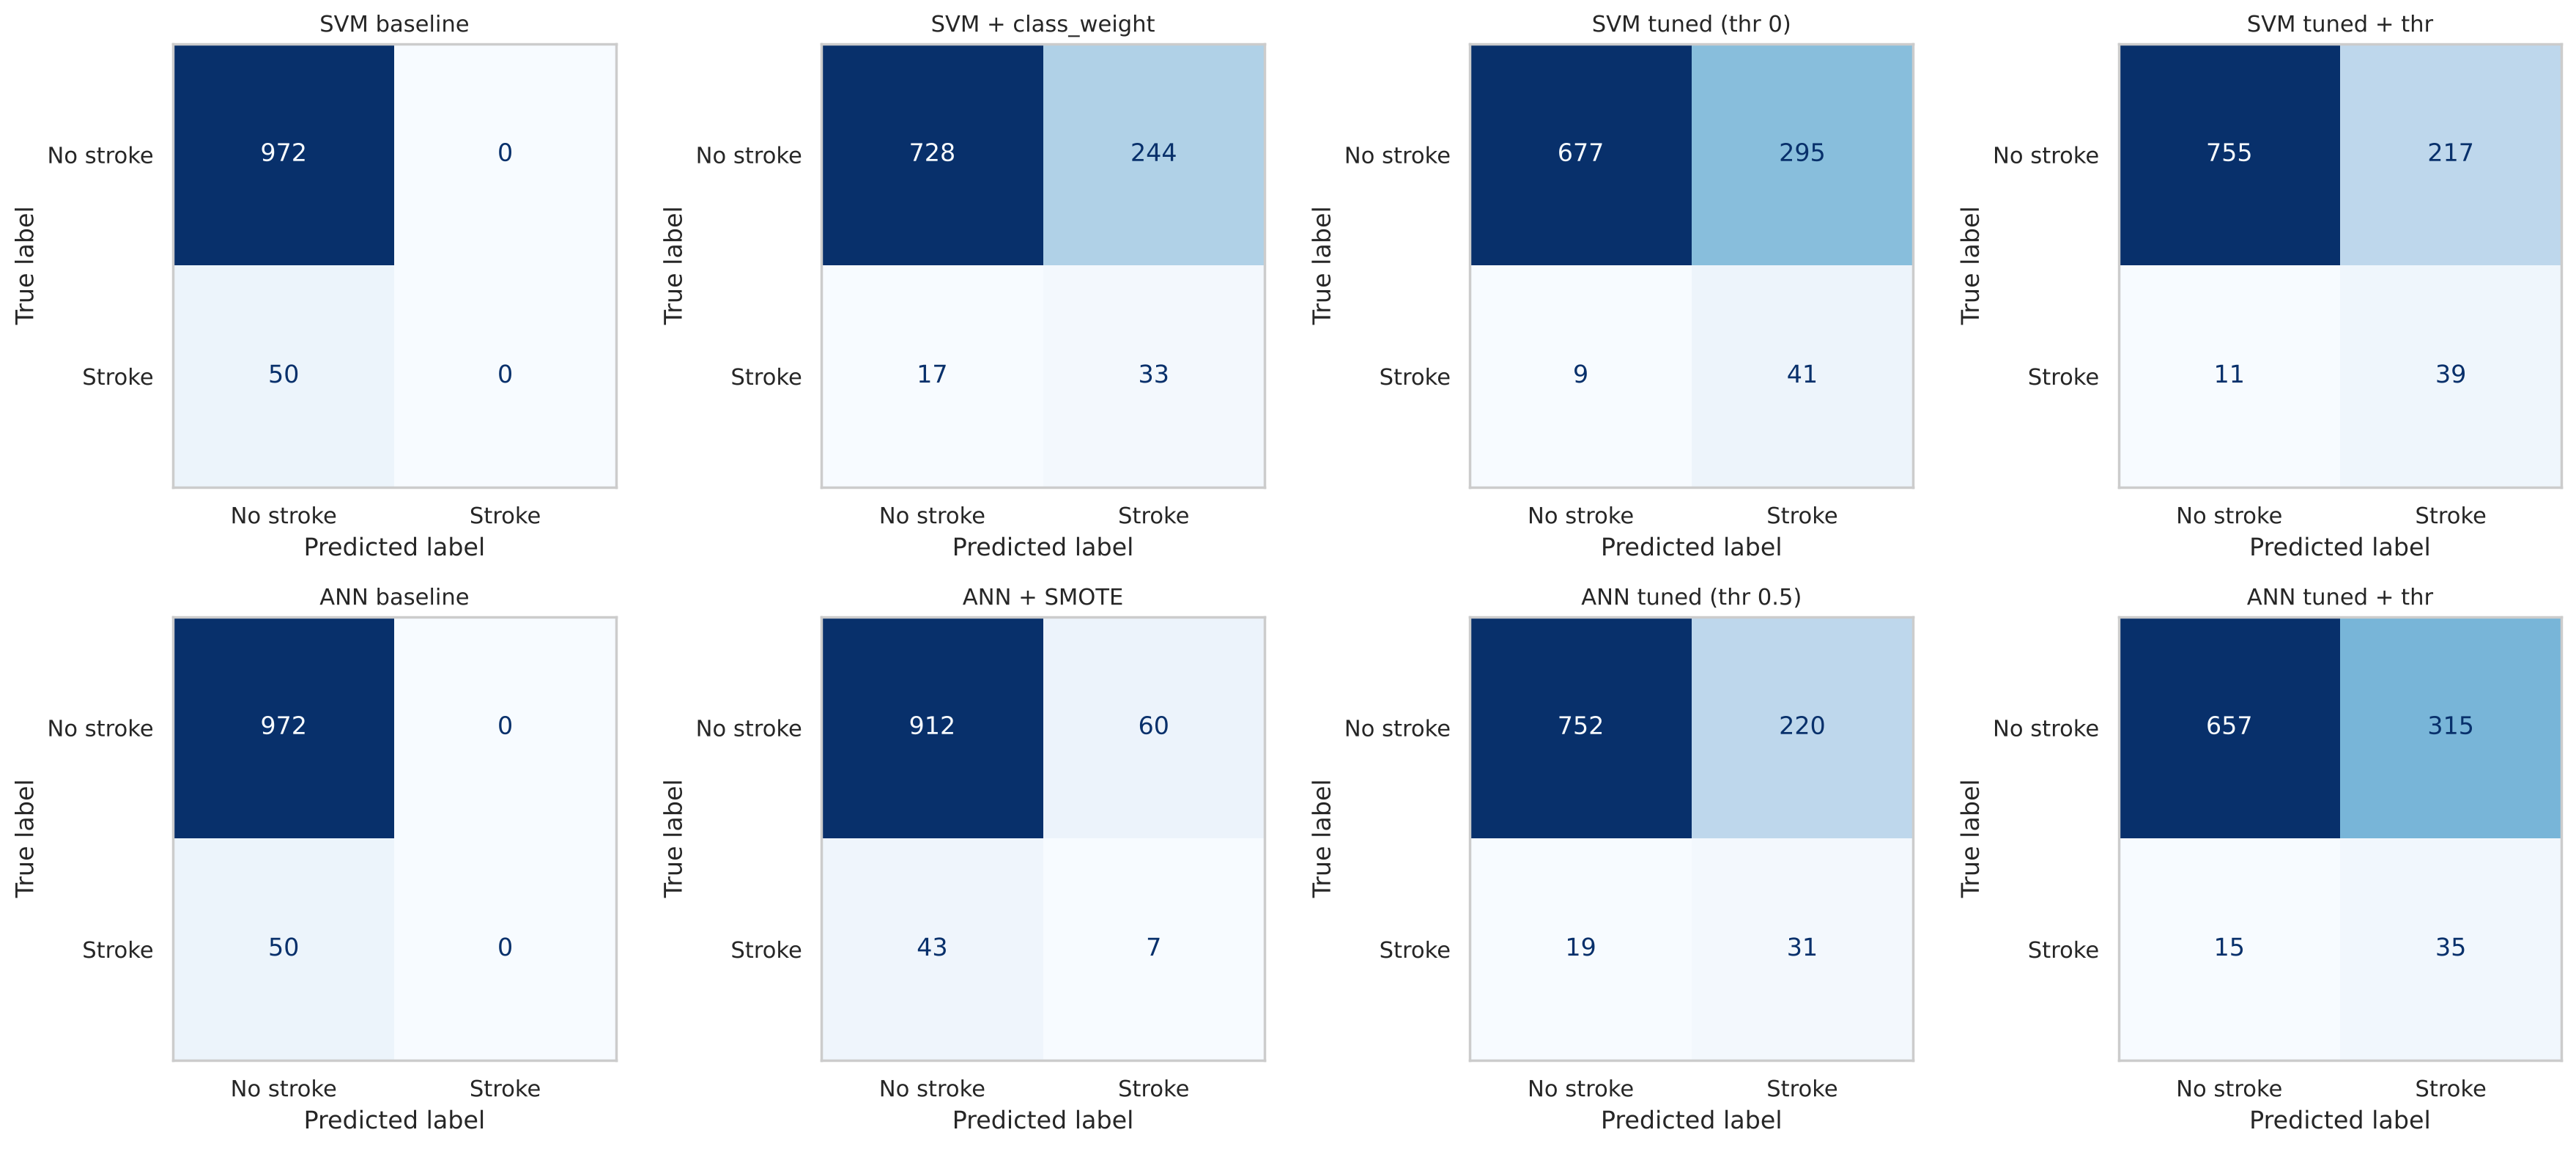

In [15]:
fig, axes = plt.subplots(2,4, figsize=(18,8)); axes=axes.ravel()
for ax,n in zip(axes,order):
    pred=(scores_te[n]>=thr[n]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test,pred), display_labels=['No stroke','Stroke']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(n, fontsize=11); ax.grid(False)
savefig('fig07_confusion_matrices')

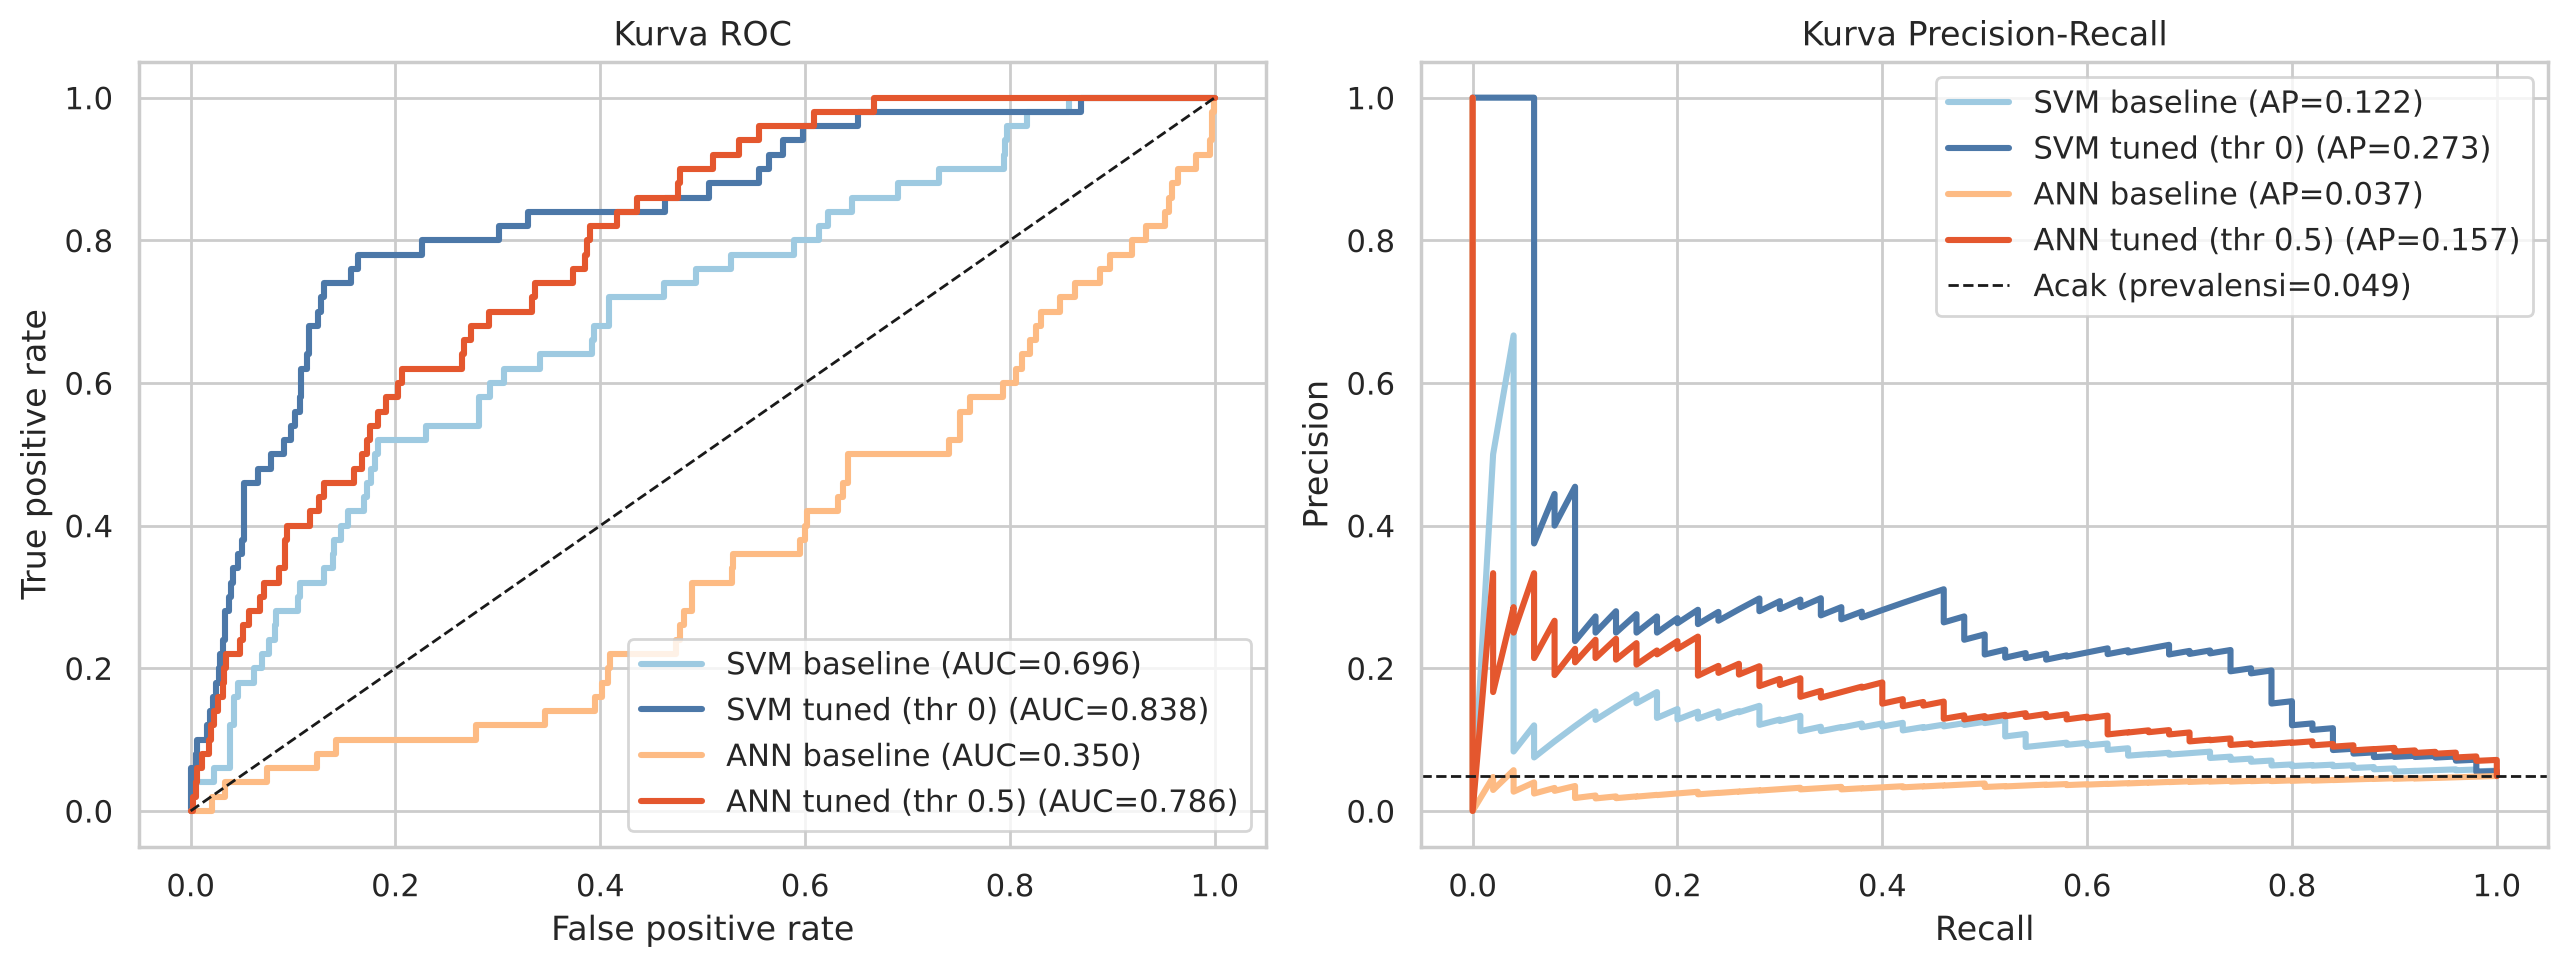

In [16]:
five = {'SVM baseline':'#9ecae1','SVM tuned (thr 0)':C_NO,'ANN baseline':'#fdbb84','ANN tuned (thr 0.5)':C_YES}
fig, axes = plt.subplots(1,2, figsize=(13,5))
for n,c in five.items():
    fpr,tpr,_ = roc_curve(y_test, scores_te[n]); axes[0].plot(fpr,tpr,color=c,lw=2.2,label=f'{n} (AUC={res.loc[n,"ROC_AUC"]:.3f})')
    pr,rc,_ = precision_recall_curve(y_test, scores_te[n]); axes[1].plot(rc,pr,color=c,lw=2.2,label=f'{n} (AP={res.loc[n,"PR_AUC"]:.3f})')
axes[0].plot([0,1],[0,1],'k--',lw=1); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].set_title('Kurva ROC'); axes[0].legend(loc='lower right')
axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Acak (prevalensi={y_test.mean():.3f})'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Kurva Precision-Recall'); axes[1].legend()
savefig('fig08_roc_pr_curves')

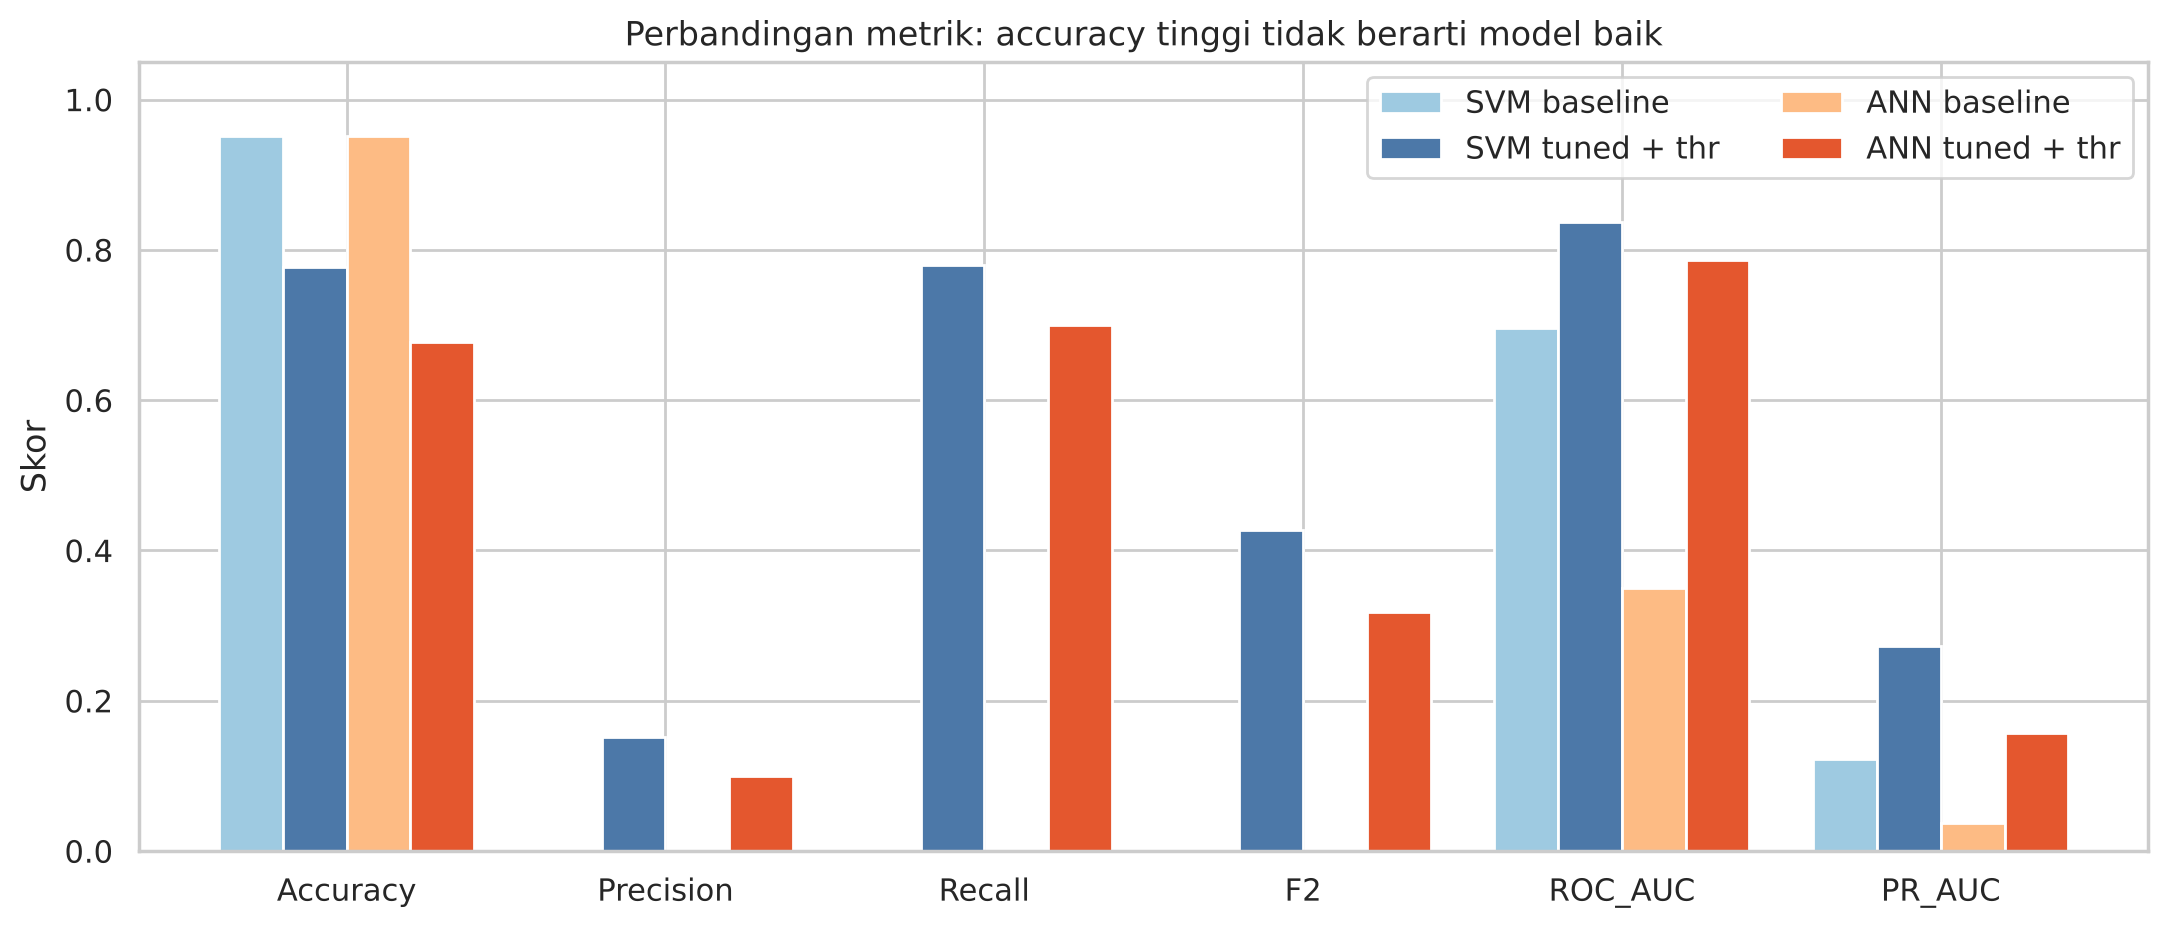

In [17]:
show = ['Accuracy','Precision','Recall','F2','ROC_AUC','PR_AUC']
sub = res.loc[['SVM baseline','SVM tuned + thr','ANN baseline','ANN tuned + thr'], show]
ax = sub.T.plot(kind='bar', figsize=(11,4.8), width=0.8, color=['#9ecae1',C_NO,'#fdbb84',C_YES]); ax.set_ylim(0,1.05)
ax.set_title('Perbandingan metrik: accuracy tinggi tidak berarti model baik'); ax.set_ylabel('Skor'); plt.xticks(rotation=0); ax.legend(loc='upper right', ncol=2)
savefig('fig09_metrics_comparison')

### 8.1 Seberapa pasti perbedaannya? Bootstrap CI & uji McNemar
Data uji hanya memiliki 50 kasus stroke, sehingga selisih kecil antar model bisa jadi hanyalah *noise*. Dilakukan **bootstrap 1.000×** untuk interval kepercayaan 95% dan **uji McNemar** untuk membandingkan prediksi kedua model.

In [18]:
rng = np.random.default_rng(RANDOM_STATE); yt = y_test.values; B=1000
s_svm, s_ann = scores_te['SVM tuned + thr'], scores_te['ANN tuned + thr']
p_svm, p_ann = (s_svm>=thr['SVM tuned + thr']).astype(int), (s_ann>=thr['ANN tuned + thr']).astype(int)
boot = {k:[] for k in ['auc_svm','auc_ann','rec_svm','rec_ann','pr_svm','pr_ann']}
for _ in range(B):
    i = rng.integers(0,len(yt),len(yt))
    if yt[i].sum()==0: continue
    boot['auc_svm'].append(roc_auc_score(yt[i],s_svm[i])); boot['auc_ann'].append(roc_auc_score(yt[i],s_ann[i]))
    boot['rec_svm'].append(recall_score(yt[i],p_svm[i])); boot['rec_ann'].append(recall_score(yt[i],p_ann[i]))
    boot['pr_svm'].append(average_precision_score(yt[i],s_svm[i])); boot['pr_ann'].append(average_precision_score(yt[i],s_ann[i]))
ci = lambda a: (np.percentile(a,2.5), np.percentile(a,97.5))
ci_tab = pd.DataFrame({'Metrik':['ROC-AUC','ROC-AUC','Recall','Recall','PR-AUC','PR-AUC'],'Model':['SVM','ANN']*3,
    'Estimasi':[res.loc['SVM tuned + thr','ROC_AUC'],res.loc['ANN tuned + thr','ROC_AUC'],res.loc['SVM tuned + thr','Recall'],res.loc['ANN tuned + thr','Recall'],res.loc['SVM tuned + thr','PR_AUC'],res.loc['ANN tuned + thr','PR_AUC']],
    'CI95_low':[ci(boot[k])[0] for k in ['auc_svm','auc_ann','rec_svm','rec_ann','pr_svm','pr_ann']],
    'CI95_high':[ci(boot[k])[1] for k in ['auc_svm','auc_ann','rec_svm','rec_ann','pr_svm','pr_ann']]}).round(3)
display(ci_tab)
d_auc = np.array(boot['auc_svm'])-np.array(boot['auc_ann'])
print(f'Selisih AUC (SVM-ANN): rata-rata={d_auc.mean():+.3f}, CI95=[{ci(d_auc)[0]:+.3f}, {ci(d_auc)[1]:+.3f}]  -> {"TIDAK " if ci(d_auc)[0]<0<ci(d_auc)[1] else ""}signifikan')

b01 = int(((p_svm==yt)&(p_ann!=yt)).sum()); b10 = int(((p_svm!=yt)&(p_ann==yt)).sum())
mc = stats.binomtest(b01, b01+b10, 0.5) if b01+b10>0 else None
print(f'McNemar: SVM benar & ANN salah={b01}, SVM salah & ANN benar={b10}, p-value={mc.pvalue:.4f}')

,Metrik,Model,Estimasi,CI95_low,CI95_high
0,ROC-AUC,SVM,0.838,0.780,0.894
1,ROC-AUC,ANN,0.786,0.738,0.838
2,Recall,SVM,0.780,0.667,0.889
3,Recall,ANN,0.700,0.569,0.826
4,PR-AUC,SVM,0.273,0.176,0.390
5,PR-AUC,ANN,0.157,0.105,0.254


Selisih AUC (SVM-ANN): rata-rata=+0.051, CI95=[+0.010, +0.093]  -> signifikan
McNemar: SVM benar & ANN salah=131, SVM salah & ANN benar=29, p-value=0.0000


### 8.2 Diagnosis overfitting dan kurva loss ANN

,Model,ROC_AUC_train,ROC_AUC_test,Gap
0,SVM tuned,0.848,0.838,0.011
1,ANN tuned,0.894,0.786,0.108


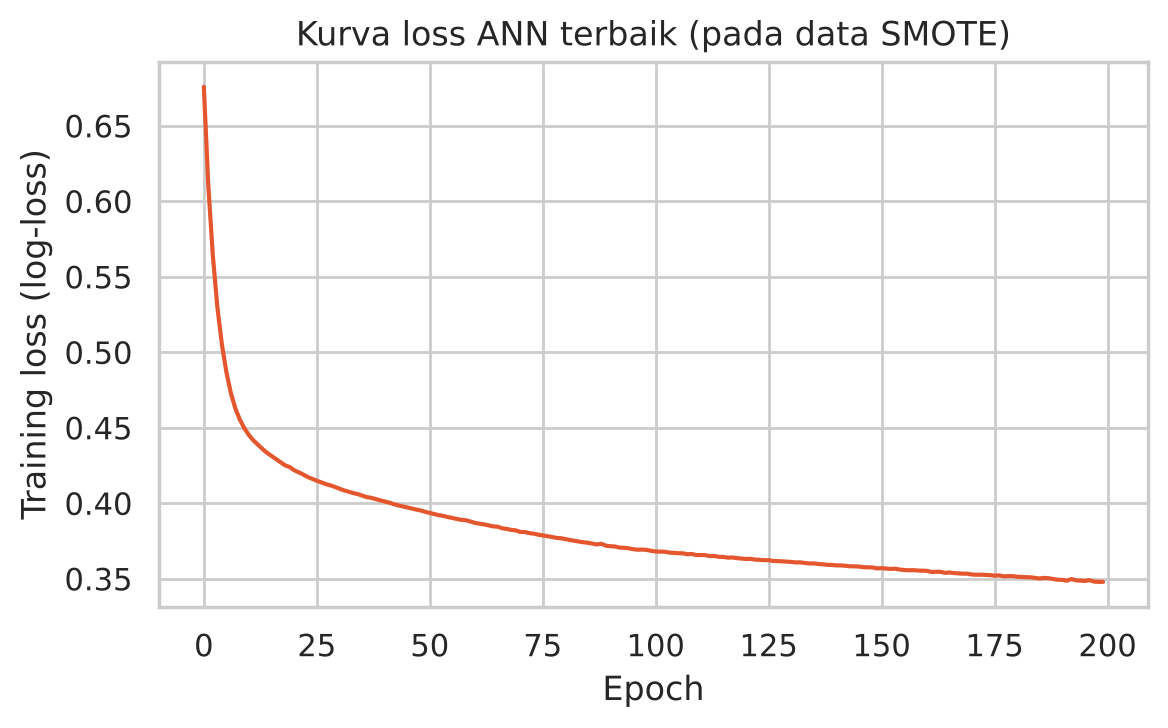

In [19]:
gap = pd.DataFrame({'Model':['SVM tuned','ANN tuned'],
  'ROC_AUC_train':[roc_auc_score(y_train,get_scores(svm_best,X_train)), roc_auc_score(y_train,get_scores(ann_best,X_train))],
  'ROC_AUC_test':[res.loc['SVM tuned + thr','ROC_AUC'], res.loc['ANN tuned + thr','ROC_AUC']]})
gap['Gap'] = gap.ROC_AUC_train-gap.ROC_AUC_test; display(gap.round(3))
loss = ann_best.named_steps['clf'].loss_curve_
fig, ax = plt.subplots(figsize=(6,3.8)); ax.plot(loss,color=C_YES); ax.set_xlabel('Epoch'); ax.set_ylabel('Training loss (log-loss)')
ax.set_title('Kurva loss ANN terbaik (pada data SMOTE)'); savefig('fig10_ann_loss_curve')

## 9. Interpretasi: fitur apa yang paling berpengaruh?

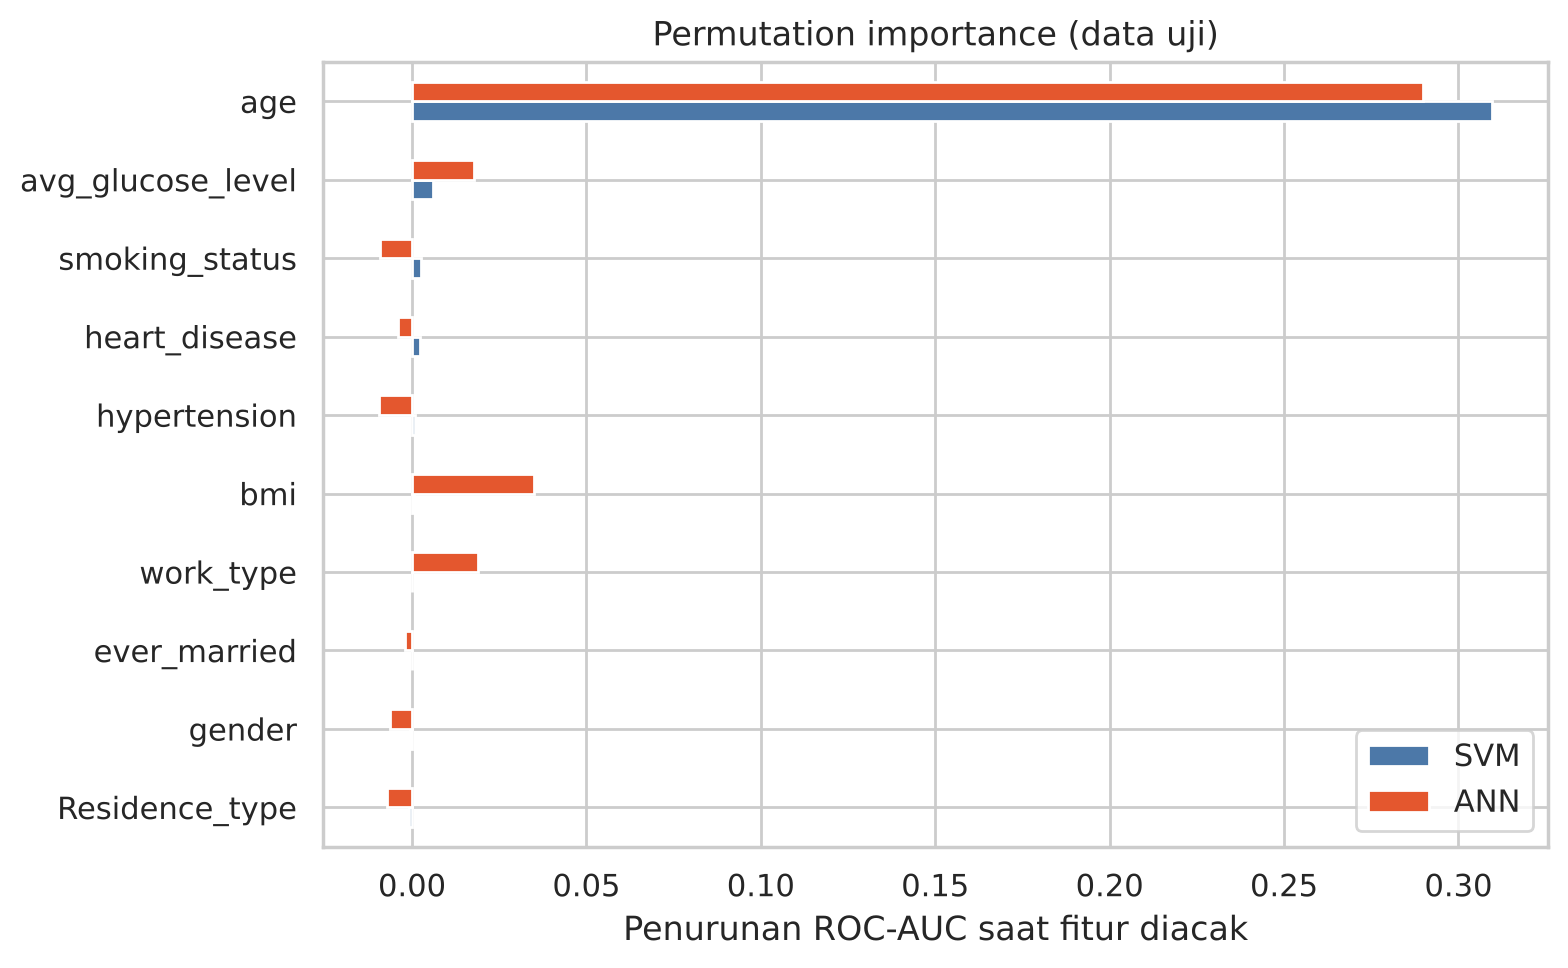

,SVM,ANN
age,0.3097,0.2898
avg_glucose_level,0.0061,0.0177
smoking_status,0.0025,-0.0090
heart_disease,0.0024,-0.0040
hypertension,0.0009,-0.0095
bmi,0.0006,0.0350
work_type,0.0001,0.0189
ever_married,0.0000,-0.0020
gender,-0.0006,-0.0064
Residence_type,-0.0010,-0.0072


In [20]:
imps = {}
for n,est in [('SVM',svm_best),('ANN',ann_best)]:
    r = permutation_importance(est, X_test, y_test, scoring='roc_auc', n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
    imps[n] = pd.Series(r.importances_mean, index=X_test.columns)
imp = pd.DataFrame(imps).sort_values('SVM')
ax = imp.plot(kind='barh', figsize=(8,5), color=[C_NO,C_YES]); ax.set_xlabel('Penurunan ROC-AUC saat fitur diacak'); ax.set_title('Permutation importance (data uji)')
savefig('fig11_permutation_importance'); display(imp.sort_values('SVM',ascending=False).round(4))

## 10. Ekspor Hasil (Tahap 2: Dokumentasi)

In [21]:
import joblib
os.makedirs('models', exist_ok=True)
joblib.dump(svm_best,'models/svm_tuned.joblib'); joblib.dump(ann_best,'models/ann_tuned.joblib')
mw.to_csv('results/eda_numeric_tests.csv',index=False); chi.to_csv('results/eda_categorical_tests.csv',index=False)
ci_tab.to_csv('results/bootstrap_ci.csv',index=False); imp.to_csv('results/permutation_importance.csv')
json.dump({'svm':{k:str(v) for k,v in svm_grid.best_params_.items()}, 'svm_cv_auc':svm_grid.best_score_, 'svm_threshold':float(t_svm),
           'ann':{k:str(v) for k,v in ann_grid.best_params_.items()}, 'ann_cv_auc':ann_grid.best_score_, 'ann_threshold':float(t_ann)},
          open('results/best_params.json','w'), indent=2)

def curve(fn, s, grid, a, b):
    x,yv,_ = fn(y_test, s); o=np.argsort(x if a=='x' else x); 
    return None
fg = np.linspace(0,1,41); rg = np.linspace(0,1,41)
def roc_pts(s): f,t,_=roc_curve(y_test,s); return np.interp(fg,f,t).round(4).tolist()
def pr_pts(s):
    p,r,_=precision_recall_curve(y_test,s); o=np.argsort(r); return np.interp(rg,r[o],p[o]).round(4).tolist()
web = {
 'n_total':int(len(df)), 'n_stroke':int(df.stroke.sum()), 'prevalence':float(df.stroke.mean()),
 'age_groups':{'labels':list(ag.index.astype(str)),'rate':ag['mean'].round(2).tolist(),'n':ag['count'].tolist()},
 'cat_cramers_v':dict(zip(chi.fitur, chi.Cramers_V)),
 'cat_rates':{c:df.groupby(c)['stroke'].mean().mul(100).round(2).to_dict() for c in ['hypertension','heart_disease','ever_married','smoking_status','work_type']},
 'models':res.round(4).reset_index().to_dict(orient='records'),
 'roc':{'fpr':fg.tolist(), **{n:roc_pts(scores_te[n]) for n in five}},
 'pr':{'recall':rg.tolist(), **{n:pr_pts(scores_te[n]) for n in five}},
 'threshold':{'svm':{'x':g_svm[::6].round(3).tolist(),'f2':f_svm[::6].round(4).tolist(),'best':float(t_svm)},
              'ann':{'x':g_ann[::6].round(3).tolist(),'f2':f_ann[::6].round(4).tolist(),'best':float(t_ann)}},
 'importance':imp.round(4).to_dict(),
 'ci':ci_tab.to_dict(orient='records'), 'mcnemar_p':float(mc.pvalue), 'auc_diff_ci':[float(ci(d_auc)[0]),float(ci(d_auc)[1])],
 'gap':gap.round(4).to_dict(orient='records'),
 'best_params':json.load(open('results/best_params.json')),
 'mw':mw.round(4).to_dict(orient='records')}
json.dump(web, open('results/website_data.json','w'), indent=1, default=float)
print('Tersimpan:', sorted(os.listdir('results')), sorted(os.listdir('figures')))

Tersimpan: ['best_params.json', 'bootstrap_ci.csv', 'eda_categorical_tests.csv', 'eda_numeric_tests.csv', 'model_comparison.csv', 'permutation_importance.csv', 'website_data.json'] ['fig01_target_distribution.png', 'fig02_numeric_distributions.png', 'fig03_categorical_stroke_rate.png', 'fig04_stroke_by_age_group.png', 'fig05_correlation_heatmap.png', 'fig06_threshold_optimization.png', 'fig07_confusion_matrices.png', 'fig08_roc_pr_curves.png', 'fig09_metrics_comparison.png', 'fig10_ann_loss_curve.png', 'fig11_permutation_importance.png']


## 11. Interpretasi Hasil

### Model mana yang lebih baik?
**SVM (RBF, C=1, gamma=0,005, class_weight='balanced') + threshold teroptimasi lebih baik daripada ANN pada dataset ini.**

| Metrik (data uji) | SVM tuned + thr | ANN tuned + thr |
|---|---|---|
| ROC-AUC | **0,838** (CI95: 0,78-0,89) | 0,786 (CI95: 0,74-0,84) |
| PR-AUC | **0,273** | 0,157 |
| Recall | **0,78** (39 dari 50 stroke terdeteksi) | 0,70 (35 dari 50) |
| Precision | **0,152** | 0,100 |
| F2 | **0,428** | 0,318 |
| Gap AUC train-test | **0,011** | 0,108 |

**Bukti statistik:** pada bootstrap berpasangan, selisih ROC-AUC SVM-ANN berada pada kisaran **+0,010 sampai +0,093**. Interval ini tidak mencakup nol, sehingga keunggulan SVM konsisten, tetapi **besarnya masih tidak pasti** karena data uji hanya memuat 50 kasus stroke. Catatan untuk uji McNemar: ia berbasis accuracy yang didominasi kelas mayoritas dan kedua model memakai threshold berbeda, jadi p-value-nya sangat kecil tetapi **tidak boleh dibaca sebagai bukti utama**. Bukti utama adalah bootstrap pada AUC/PR-AUC/recall.

**Mengapa SVM unggul di sini?**
1. **Ukuran data kecil dan sinyal lemah:** hanya 249 kasus stroke. SVM bermargin maksimum memiliki regularisasi bawaan yang kuat, sedangkan ANN lebih mudah menghafal derau (gap train-test 0,108 vs 0,011).
2. **Cara menangani imbalance:** SVM memakai `class_weight` yang tidak menambah data buatan, sedangkan ANN bergantung pada SMOTE yang menghasilkan sampel sintetis (pecahan pada kolom one-hot).
3. **Fitur tabular dengan dimensi rendah (±17 kolom):** kondisi ini umumnya tidak menguntungkan jaringan saraf dibanding metode klasik.

### Mengapa accuracy saja tidak cukup?
- **SVM baseline** dan **ANN baseline** memiliki accuracy **95,1%**, tetapi **recall 0%**: keduanya tidak menemukan satu pun dari 50 pasien stroke. Accuracy-nya identik dengan model yang selalu menjawab "tidak stroke".
- Model terbaik **hanya memiliki accuracy 77,7%**, tetapi mendeteksi **39 dari 50** pasien stroke. Dalam *screening*, ini jauh lebih bermanfaat.
- ANN baseline bahkan memiliki ROC-AUC 0,35 (di bawah tebakan acak). Ini tanda model gagal belajar pola kelas minoritas, bukan sekadar threshold yang kurang pas.

### Insight dari data dan model
1. **Usia adalah faktor dominan.** Median usia pasien stroke 71 tahun vs 43 tahun. Stroke rate naik dari <2% (di bawah 50 tahun) menjadi 17,8% pada kelompok 70+. Pada permutation importance, **usia menyumbang hampir seluruh kekuatan prediksi** kedua model (penurunan AUC ±0,30 vs <0,04 untuk fitur lain).
2. Faktor klinis (**penyakit jantung, hipertensi, glukosa darah**) berhubungan signifikan dengan stroke secara univariat, tetapi **kontribusi tambahannya kecil setelah usia diperhitungkan**.
3. **Gender dan tipe tempat tinggal** tidak informatif (p > 0,05).
4. Hubungan antara fitur lain dan stroke sebagian besar tercampur dengan usia (contoh: `ever_married`, `work_type = children`). Ini **asosiasi, bukan kausalitas**.

### Trade-off yang harus diakui
Pada threshold terpilih, **precision hanya ±15%**: setiap pasien stroke yang terdeteksi disertai ±5-6 alarm palsu. Ini wajar untuk *screening* tahap awal (yang kemudian diikuti pemeriksaan lanjutan), tetapi **bukan alat diagnosis**.

## 12. Keterbatasan & Langkah Lanjutan
- Data uji hanya 50 kasus positif, sehingga estimasi metrik bersifat tidak stabil (lihat lebar CI). *Repeated stratified CV* akan lebih andal.
- SMOTE setelah one-hot encoding kurang ideal; coba **SMOTENC**, `class_weight` pada ANN berbasis Keras/PyTorch, atau *focal loss*.
- ANN mungkin bisa lebih baik dengan arsitektur/regularisasi yang lebih luas (dropout, early stopping), meski potensi kenaikannya pada data tabular sekecil ini terbatas.
- Bandingkan dengan **Logistic Regression**, **Random Forest**, dan **Gradient Boosting** sebagai baseline yang kuat.
- Gunakan **kalibrasi probabilitas** bila model akan dipakai untuk estimasi risiko.
- Model ini ditujukan untuk **pembelajaran/portofolio**, bukan penggunaan klinis.